In [1]:
import pandas as pd
import numpy as np

print("MediLens setup ready!")

MediLens setup ready!


In [2]:
df = pd.read_csv("../data/healthcare_dataset.csv")

In [3]:
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


Rows and Columns

In [4]:
df.shape

(55500, 15)

Columns

In [5]:
df.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='str')

Data types and basic information

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  str    
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  str    
 3   Blood Type          55500 non-null  str    
 4   Medical Condition   55500 non-null  str    
 5   Date of Admission   55500 non-null  str    
 6   Doctor              55500 non-null  str    
 7   Hospital            55500 non-null  str    
 8   Insurance Provider  55500 non-null  str    
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  str    
 12  Discharge Date      55500 non-null  str    
 13  Medication          55500 non-null  str    
 14  Test Results        55500 non-null  str    
dtypes: float64(1), int64(2), str(12)
memory usage: 6.4 MB


Missing Values

In [7]:
df.isnull().sum()

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

Duplicate records

In [8]:
df.duplicated().sum()

np.int64(534)

Basic numerical statistics

In [9]:
df.describe()

,Age,Billing Amount,Room Number
count,55500.000000,55500.000000,55500.000000
mean,51.539459,25539.316097,301.134829
std,19.602454,14211.454431,115.243069
min,13.000000,-2008.492140,101.000000
25%,35.000000,13241.224652,202.000000
50%,52.000000,25538.069376,302.000000
75%,68.000000,37820.508436,401.000000
max,89.000000,52764.276736,500.000000


Data Cleaning

In [10]:
clean_df = df.copy()

In [11]:
clean_df = clean_df.drop_duplicates()

In [12]:
clean_df.shape

(54966, 15)

Investigation

In [13]:
negative_billing = clean_df[clean_df['Billing Amount'] < 0]
negative_billing.shape

(106, 15)

In [14]:
negative_billing[['Name', 'Billing Amount', 'Medical Condition','Hospital']]

,Name,Billing Amount,Medical Condition,Hospital
132,ashLEy ERIcKSoN,-502.507813,Cancer,"and Johnson Moore, Branch"
799,CHRisTOPHer wEiss,-1018.245371,Asthma,Hunter-Hughes
1018,AsHley WaRnER,-306.364925,Hypertension,"and Wagner, Lee Klein"
1421,JAY galloWaY,-109.097122,Asthma,Group Peters
2103,josHUa wilLIamSon,-576.727907,Diabetes,"and Huff Reeves, Dennis"
...,...,...,...,...
52213,mr. ChRIStOPhER aLvARaDO,-1310.272895,Obesity,Johnson Inc
52629,gABrieLlE deCkER,-676.852502,Arthritis,Diaz-Bishop
53204,AsHley WaRnER,-306.364925,Hypertension,"and Wagner, Lee Klein"
53232,dAnIel dRaKe,-591.917419,Hypertension,Carr Ltd


Removing Negative Billing Amount

In [15]:
clean_df = clean_df[clean_df['Billing Amount'] >= 0]

Verifying

In [16]:
clean_df[clean_df['Billing Amount'] < 0].shape

(0, 15)

Converting Dates

In [17]:
clean_df['Date of Admission'] = pd.to_datetime(clean_df['Date of Admission'])
clean_df['Discharge Date'] = pd.to_datetime(clean_df['Discharge Date'])

In [18]:
clean_df['Length of Stay'] = (clean_df['Discharge Date'] - clean_df['Date of Admission']).dt.days

In [19]:
clean_df[['Date of Admission', 'Discharge Date', 'Length of Stay']].head()

,Date of Admission,Discharge Date,Length of Stay
0,2024-01-31,2024-02-02,2
1,2019-08-20,2019-08-26,6
2,2022-09-22,2022-10-07,15
3,2020-11-18,2020-12-18,30
4,2022-09-19,2022-10-09,20


In [20]:
clean_df[clean_df['Length of Stay'] < 0].shape

(0, 16)

Data Analysing

In [21]:
clean_df['Admission Year'] = clean_df['Date of Admission'].dt.year

In [22]:
clean_df[['Date of Admission', 'Admission Year']]

,Date of Admission,Admission Year
0,2024-01-31,2024
1,2019-08-20,2019
2,2022-09-22,2022
3,2020-11-18,2020
4,2022-09-19,2022
...,...,...
55495,2020-08-16,2020
55496,2020-01-23,2020
55497,2020-07-13,2020
55498,2019-05-25,2019


Medical Condition-wise Patients

In [23]:
condition_counts = clean_df.groupby('Medical Condition').size()
condition_counts

Medical Condition
Arthritis       9207
Asthma          9077
Cancer          9121
Diabetes        9197
Hypertension    9131
Obesity         9127
dtype: int64

Average Billing by Medical Condition

In [24]:
condition_billing = clean_df.groupby('Medical Condition')['Billing Amount'].mean().sort_values(ascending=False)
condition_billing

Medical Condition
Obesity         25859.215373
Diabetes        25714.326349
Asthma          25685.385020
Hypertension    25559.844868
Arthritis       25542.898356
Cancer          25205.924207
Name: Billing Amount, dtype: float64

Admission Type Analysis

In [25]:
admission_counts = clean_df.groupby('Admission Type').size()
admission_counts

Admission Type
Elective     18437
Emergency    18070
Urgent       18353
dtype: int64

Average Length of Stay by Condition

In [26]:
stay_by_condition = clean_df.groupby('Medical Condition')['Length of Stay'].mean().sort_values(ascending=False)
stay_by_condition

Medical Condition
Asthma          15.676104
Cancer          15.510141
Arthritis       15.503747
Obesity         15.439465
Hypertension    15.435440
Diabetes        15.429488
Name: Length of Stay, dtype: float64

Gender Analysis

In [27]:
gender_counts = clean_df.groupby('Gender').size()
gender_counts

Gender
Female    27411
Male      27449
dtype: int64

Average Billing

In [28]:
gender_billing = clean_df.groupby('Gender')['Billing Amount'].mean()
gender_billing

Gender
Female    25529.935010
Male      25659.242696
Name: Billing Amount, dtype: float64

Year-wise Admissions

In [29]:
yearly_admissions = clean_df.groupby('Admission Year').size()
yearly_admissions

Admission Year
2019     7280
2020    11157
2021    10795
2022    10891
2023    10918
2024     3819
dtype: int64

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

Medical Condition-wise Patient Chart

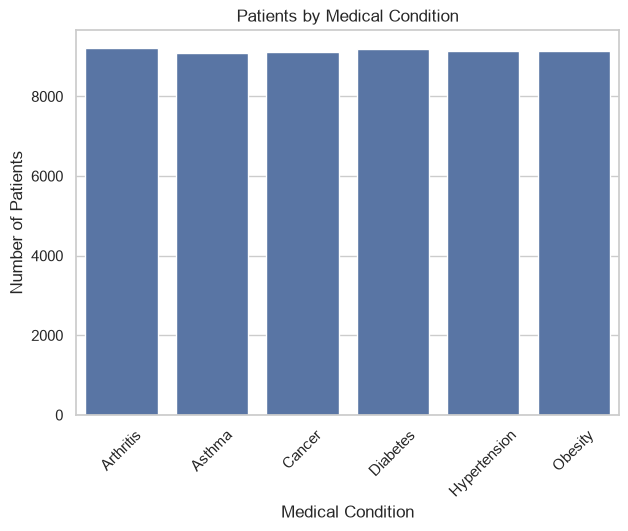

In [31]:
plt.figure(figsize=(7, 5))
sns.barplot(x=condition_counts.index, y=condition_counts.values)
plt.title("Patients by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.show()

Admission Type Chart

Text(0, 0.5, 'Number of Patients')

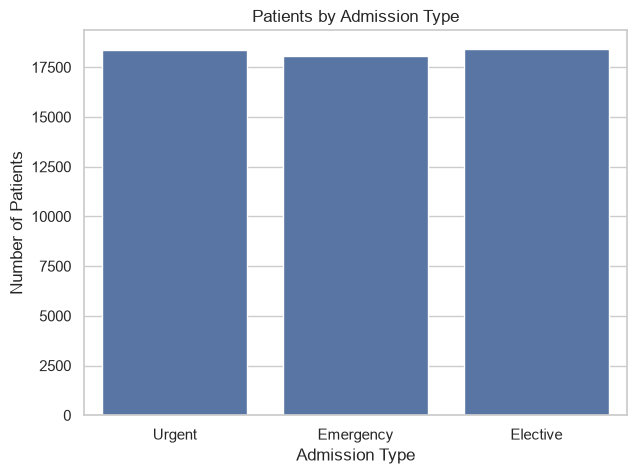

In [32]:
plt.figure(figsize=(7, 5))
sns.countplot(data=clean_df,x='Admission Type')
plt.title("Patients by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Number of Patients")

Gender Analysis

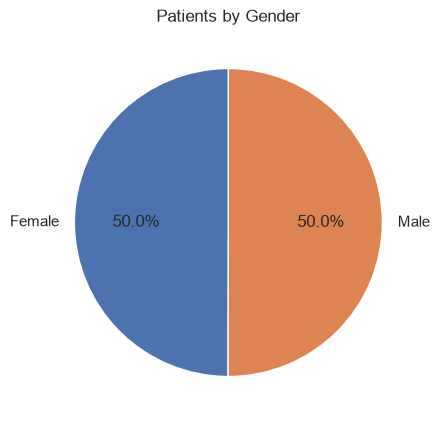

In [33]:
plt.figure(figsize=(7, 5))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%', startangle=90)
plt.title("Patients by Gender")
plt.show()

Average Billing by Gender

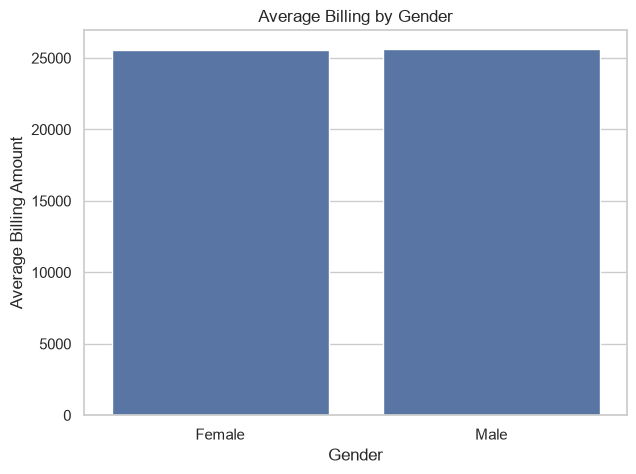

In [34]:
plt.figure(figsize=(7, 5))
sns.barplot(x=gender_billing.index, y=gender_billing.values)
plt.title("Average Billing by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Billing Amount")
plt.show()

Year-wise Admission

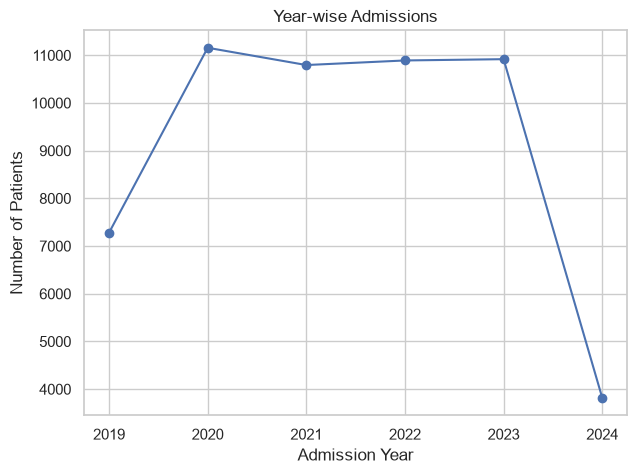

In [35]:
plt.figure(figsize=(7, 5))
plt.plot(yearly_admissions.index, yearly_admissions.values, marker='o')
plt.title("Year-wise Admissions")
plt.xlabel("Admission Year")
plt.ylabel("Number of Patients")
plt.xticks(yearly_admissions.index)
plt.grid(True)
plt.show()

Average Billing by Medical Condition

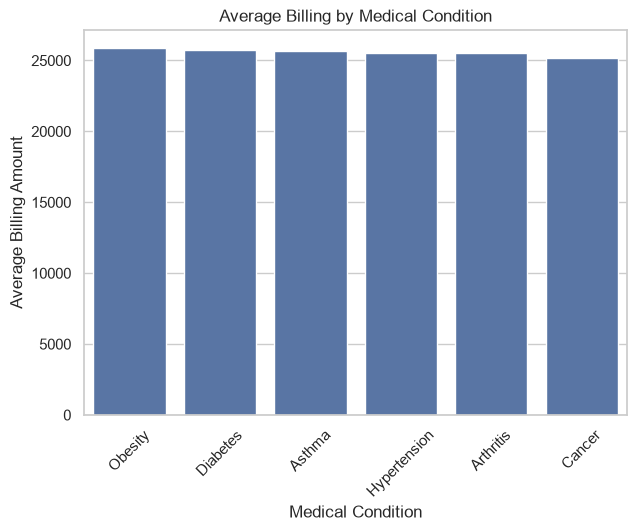

In [36]:
plt.figure(figsize=(7, 5))
sns.barplot(x=condition_billing.index, y=condition_billing.values)
plt.title("Average Billing by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Average Billing Amount")
plt.xticks(rotation=45)
plt.show()

Age Distribution of Patients

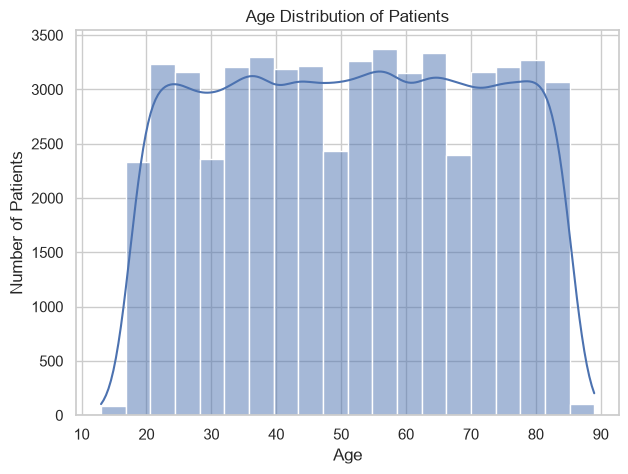

In [37]:
plt.figure(figsize=(7, 5))
sns.histplot(data=clean_df, x='Age', bins=20, kde=True)
plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

Age vs Billing Amount

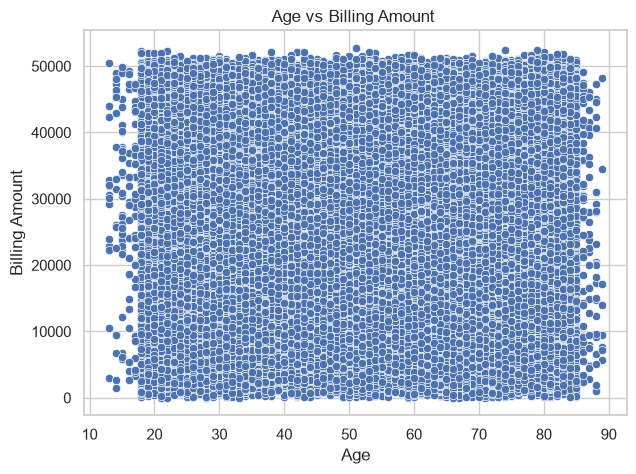

In [38]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=clean_df, x="Age",y="Billing Amount")
plt.title("Age vs Billing Amount ")
plt.xlabel("Age")
plt.ylabel("Billing Amount")
plt.show()

Average Type vs Average Billing Amount

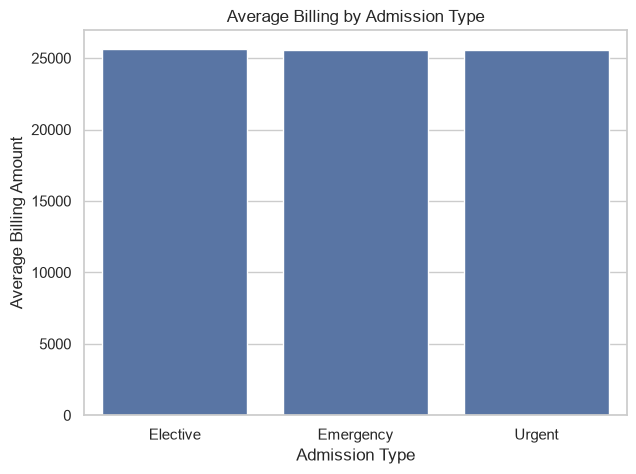

In [39]:
admission_billing = clean_df.groupby('Admission Type')['Billing Amount'].mean()
plt.figure(figsize=(7,5))
sns.barplot(x=admission_billing.index, y=admission_billing.values)
plt.title("Average Billing by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Average Billing Amount")
plt.show()

Medical Condition vs Gender

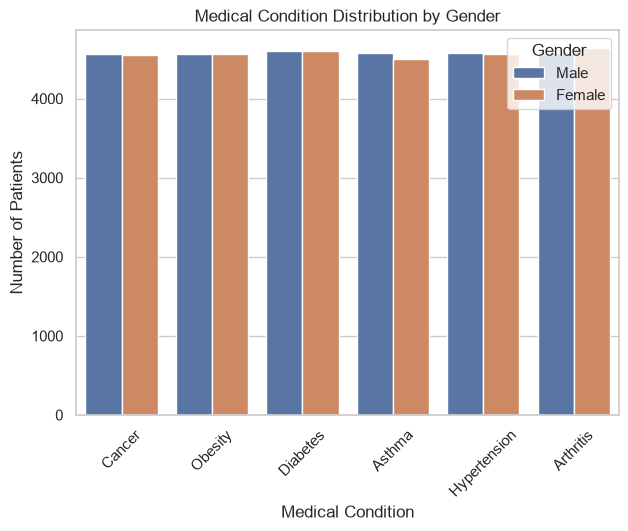

In [40]:
plt.figure(figsize=(7,5))
sns.countplot(data=clean_df,x='Medical Condition',hue='Gender')
plt.title("Medical Condition Distribution by Gender")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.show()

Insurance Provider Analysis

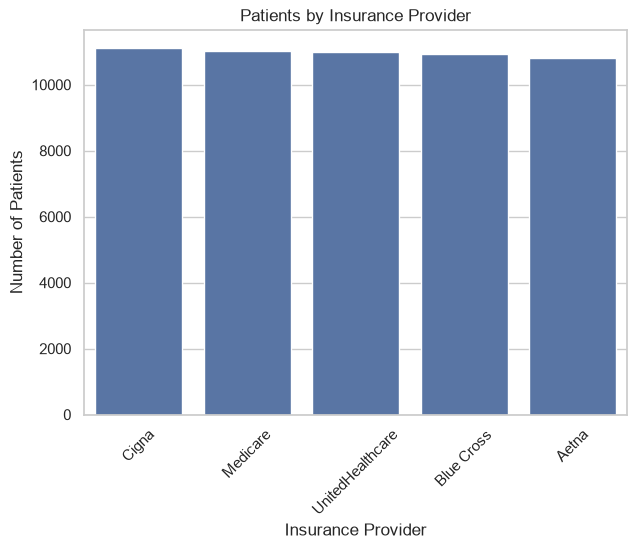

In [41]:
insurance_counts = clean_df['Insurance Provider'].value_counts()
plt.figure(figsize=(7,5))
sns.barplot(x=insurance_counts.index, y=insurance_counts.values)
plt.title("Patients by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.show()

Average Billing vs Insurance Provider

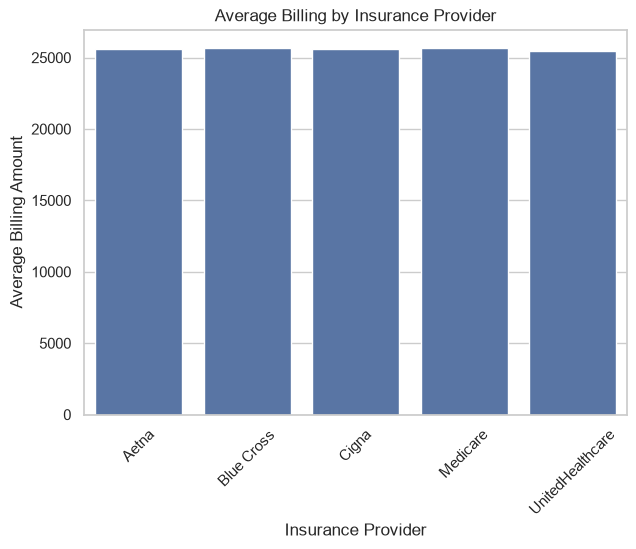

In [42]:
insurance_billing = clean_df.groupby('Insurance Provider')['Billing Amount'].mean()
plt.figure(figsize=(7,5))
sns.barplot(x=insurance_billing.index, y=insurance_billing.values)
plt.title("Average Billing by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Average Billing Amount")
plt.xticks(rotation=45)
plt.show()

Test Result Analysis

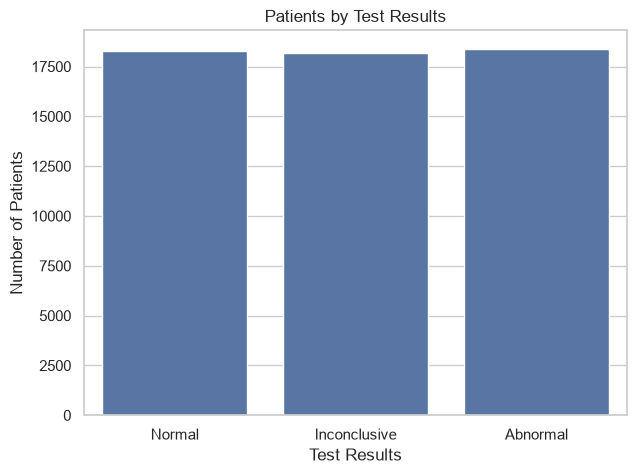

In [43]:
plt.figure(figsize=(7,5))
sns.countplot(data=clean_df,x='Test Results')
plt.title("Patients by Test Results")
plt.xlabel("Test Results")
plt.ylabel("Number of Patients")
plt.show()

Medication Analysis

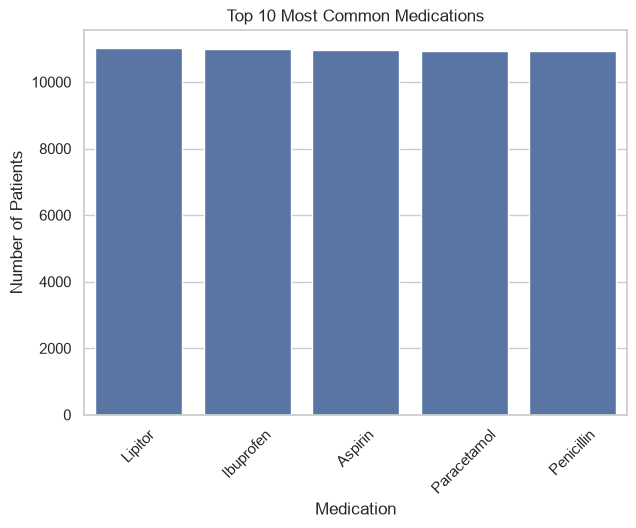

In [44]:
medication_counts = clean_df['Medication'].value_counts().head(10)
plt.figure(figsize=(7,5))
sns.barplot(x=medication_counts.index, y=medication_counts.values)
plt.title("Top 10 Most Common Medications")
plt.xlabel("Medication")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.show()

Length of Stay Distribution

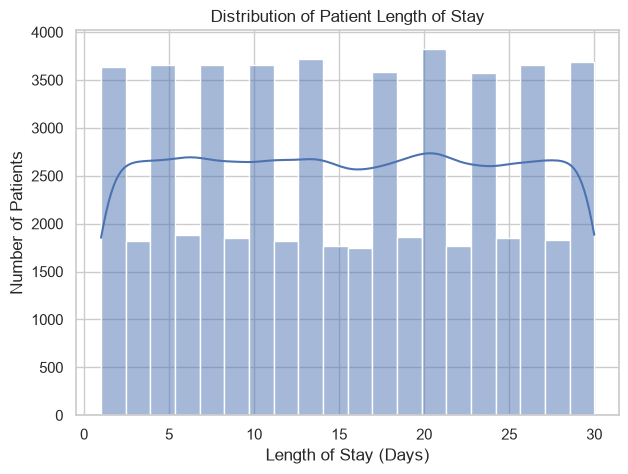

In [45]:
plt.figure(figsize=(7,5))
sns.histplot(data=clean_df, x='Length of Stay', bins=20, kde=True)
plt.title('Distribution of Patient Length of Stay')
plt.xlabel('Length of Stay (Days)')
plt.ylabel('Number of Patients')
plt.show()

Average Billing by Length of Stay

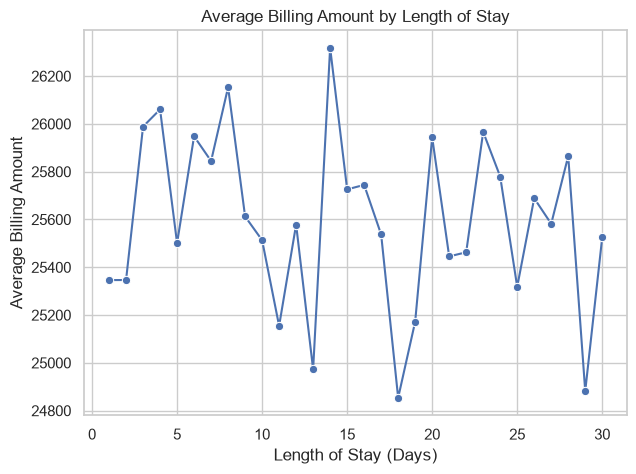

In [46]:
stay_billing = clean_df.groupby('Length of Stay')['Billing Amount'].mean()
plt.figure(figsize=(7,5))
sns.lineplot(x=stay_billing.index, y=stay_billing.values, marker='o')
plt.title('Average Billing Amount by Length of Stay')
plt.xlabel('Length of Stay (Days)')
plt.ylabel('Average Billing Amount')
plt.show()

Correlation Analysis

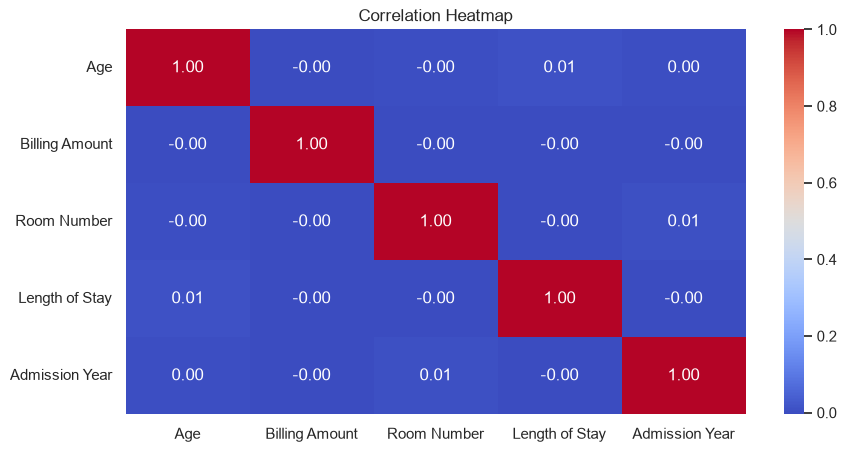

In [47]:
plt.figure(figsize=(10,5))
corr = clean_df.select_dtypes(include=['number']).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

Length of Stay vs Billing Amount- Correlation

In [48]:
stay_billing_corr = clean_df[['Length of Stay', 'Billing Amount']].corr()
stay_billing_corr

,Length of Stay,Billing Amount
Length of Stay,1.000000,-0.004801
Billing Amount,-0.004801,1.000000


In [49]:
correlation = clean_df['Length of Stay'].corr(clean_df['Billing Amount'])
print("Correlation between Length of Stay and Billing Amount:", correlation)

Correlation between Length of Stay and Billing Amount: -0.004800992285179229


Medical Condition- Highest & Lowest Average Billing 

In [50]:
condition_billing = clean_df.groupby('Medical Condition')['Billing Amount'].mean().sort_values(ascending=False)
print('Highest Average Billing:')
print(condition_billing.head(1))
print('\nLowest Average Billing:')
print(condition_billing.tail(1))

Highest Average Billing:
Medical Condition
Obesity    25859.215373
Name: Billing Amount, dtype: float64

Lowest Average Billing:
Medical Condition
Cancer    25205.924207
Name: Billing Amount, dtype: float64


Admission Type- Highest & Lowest Average Billing

In [51]:
admission_billing = clean_df.groupby('Admission Type')['Billing Amount'].mean().sort_values(ascending=False)
print('Highest Average Billing:')
print(admission_billing.head(1))
print('\nLowest Average Billing:')
print(admission_billing.tail(1))

Highest Average Billing:
Admission Type
Elective    25663.342261
Name: Billing Amount, dtype: float64

Lowest Average Billing:
Admission Type
Emergency    25551.133763
Name: Billing Amount, dtype: float64


Gender Billing Difference

In [52]:
gender_billing = clean_df.groupby('Gender')['Billing Amount'].mean()
print(gender_billing)
difference = abs(gender_billing['Male'] - gender_billing['Female'])
print('\nDifference in Average Billing:', difference)

Gender
Female    25529.935010
Male      25659.242696
Name: Billing Amount, dtype: float64

Difference in Average Billing: 129.30768614233602


Year-wise Admission- Highest & Lowest Year

In [53]:
yearly_admissions = clean_df.groupby('Admission Year').size()
print('Highest Admissions:')
print(yearly_admissions.idxmax(), yearly_admissions.max())
print('\nLowest Admissions:')
print(yearly_admissions.idxmin(), yearly_admissions.min())

Highest Admissions:
2020 11157

Lowest Admissions:
2024 3819


Medical Condition vs Test Results

In [54]:
condition_test = pd.crosstab(clean_df['Medical Condition'], clean_df['Test Results'])
condition_test

Test Results,Abnormal,Inconclusive,Normal
Medical Condition,,,
Arthritis,3153,3061,2993
Asthma,2972,2992,3113
Cancer,3081,3029,3011
Diabetes,3124,3014,3059
Hypertension,2970,3060,3101
Obesity,3099,3003,3025


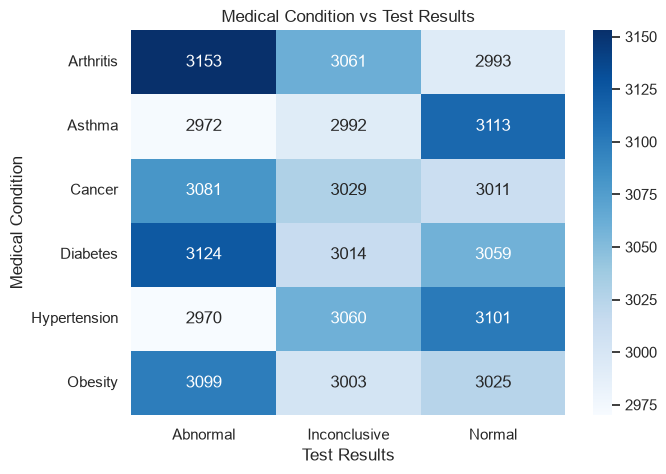

In [55]:
plt.figure(figsize=(7,5))
sns.heatmap(condition_test, annot=True, fmt='d', cmap='Blues')
plt.title('Medical Condition vs Test Results')
plt.xlabel('Test Results')
plt.ylabel('Medical Condition')
plt.show()

Create Age Groups

In [56]:
clean_df['Age Group'] = pd.cut(clean_df['Age'],bins=[0, 18, 35, 50, 65, 100],labels=['0-18', '19-35', '36-50', '51-65', '66+'],include_lowest=True)
clean_df['Age Group'].value_counts().sort_index()

Age Group
0-18       885
19-35    13491
36-50    12143
51-65    12277
66+      16064
Name: count, dtype: int64

Age Group vs Medical Condition

In [57]:
age_condition = pd.crosstab(clean_df['Age Group'], clean_df['Medical Condition'])
age_condition

Medical Condition,Arthritis,Asthma,Cancer,Diabetes,Hypertension,Obesity
Age Group,,,,,,
0-18,148,150,146,140,143,158
19-35,2256,2263,2267,2213,2228,2264
36-50,2061,1975,1982,2091,2008,2026
51-65,2029,1976,2047,2084,2042,2099
66+,2713,2713,2679,2669,2710,2580


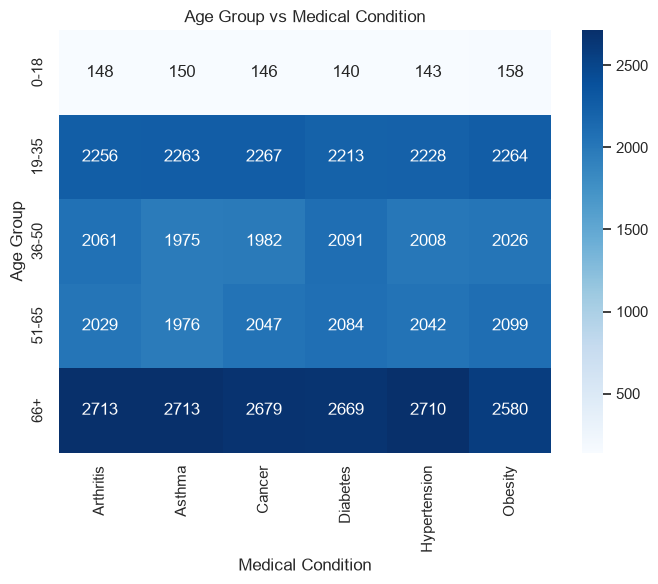

In [58]:
plt.figure(figsize=(7, 6))
sns.heatmap(age_condition,annot=True,fmt='d',cmap='Blues')
plt.title('Age Group vs Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Age Group')
plt.tight_layout()
plt.show()

Admission Type vs Test Results

In [59]:
admission_test = pd.crosstab(clean_df['Admission Type'],clean_df['Test Results'])
admission_test

Test Results,Abnormal,Inconclusive,Normal
Admission Type,,,
Elective,6220,6039,6178
Emergency,6029,6005,6036
Urgent,6150,6115,6088


<Figure size 700x500 with 0 Axes>

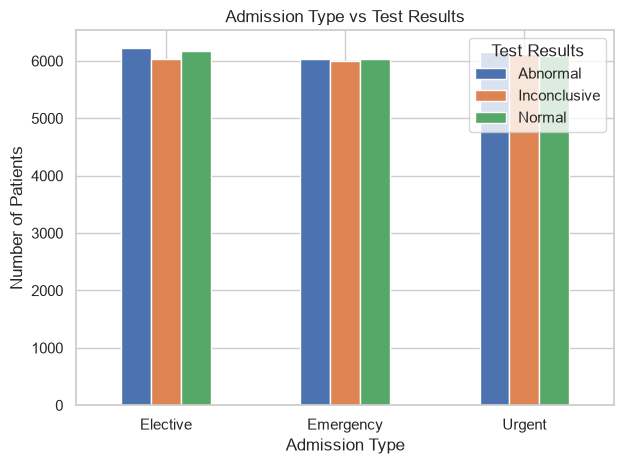

In [60]:
plt.figure(figsize=(7, 5))
admission_test.plot(kind='bar')
plt.title('Admission Type vs Test Results')
plt.xlabel('Admission Type')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Insurance Provider vs Billing Amount

In [61]:
insurance_billing = (clean_df.groupby('Insurance Provider')['Billing Amount'].mean().sort_values(ascending=False))
insurance_billing

Insurance Provider
Medicare            25678.087847
Blue Cross          25639.269835
Aetna               25615.260975
Cigna               25582.227724
UnitedHealthcare    25458.893302
Name: Billing Amount, dtype: float64

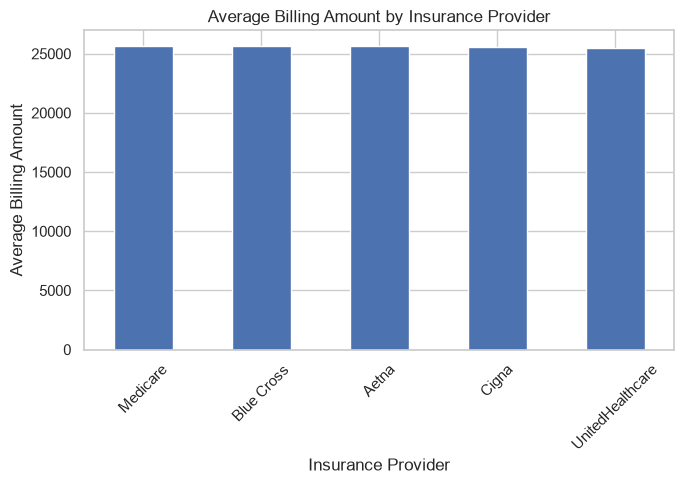

In [62]:
plt.figure(figsize=(7, 5))
insurance_billing.plot(kind='bar')
plt.title('Average Billing Amount by Insurance Provider')
plt.xlabel('Insurance Provider')
plt.ylabel('Average Billing Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Hospital-wise Patient Count

In [63]:
hospital_patients = (clean_df['Hospital'].value_counts().head(10))
hospital_patients

Hospital
LLC Smith      44
Ltd Smith      39
Johnson PLC    37
Smith Ltd      37
Smith PLC      36
Smith Group    34
Smith Inc      33
Smith LLC      32
Group Smith    32
Johnson Inc    32
Name: count, dtype: int64

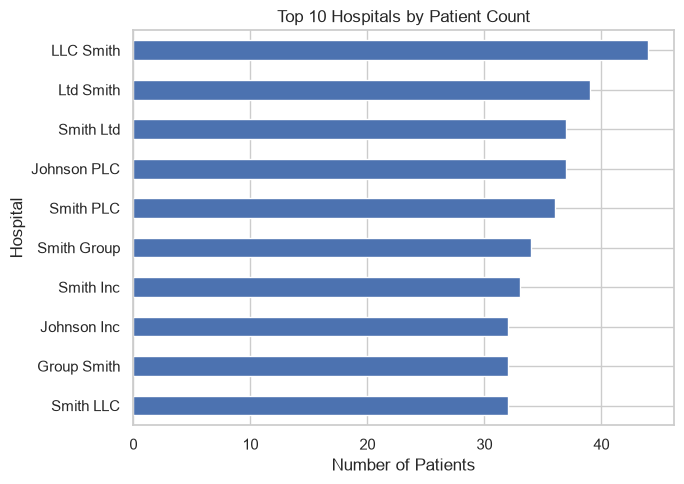

In [64]:
plt.figure(figsize=(7, 5))
hospital_patients.sort_values().plot(kind='barh')
plt.title('Top 10 Hospitals by Patient Count')
plt.xlabel('Number of Patients')
plt.ylabel('Hospital')
plt.tight_layout()
plt.show()

Doctor-wise Patient Count

In [65]:
doctor_patients = (clean_df['Doctor'].value_counts().head(10))
doctor_patients

Doctor
Michael Smith       27
John Smith          22
Robert Smith        21
Michael Johnson     20
James Smith         19
Robert Johnson      19
David Smith         19
Michael Williams    18
Matthew Smith       17
John Johnson        17
Name: count, dtype: int64

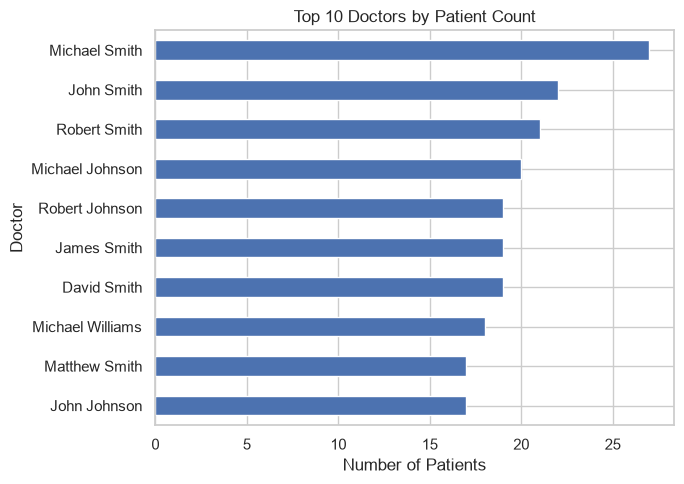

In [66]:
plt.figure(figsize=(7, 5))
doctor_patients.sort_values().plot(kind='barh')
plt.title('Top 10 Doctors by Patient Count')
plt.xlabel('Number of Patients')
plt.ylabel('Doctor')
plt.tight_layout()
plt.show()

Test Results vs Medical Condition

In [67]:
condition_test_percentage = pd.crosstab(clean_df['Medical Condition'],clean_df['Test Results'],normalize='index') * 100
condition_test_percentage

Test Results,Abnormal,Inconclusive,Normal
Medical Condition,,,
Arthritis,34.245683,33.246443,32.507874
Asthma,32.742095,32.962433,34.295472
Cancer,33.779191,33.209078,33.011731
Diabetes,33.967598,32.771556,33.260846
Hypertension,32.526558,33.512211,33.961231
Obesity,33.954202,32.902378,33.143421


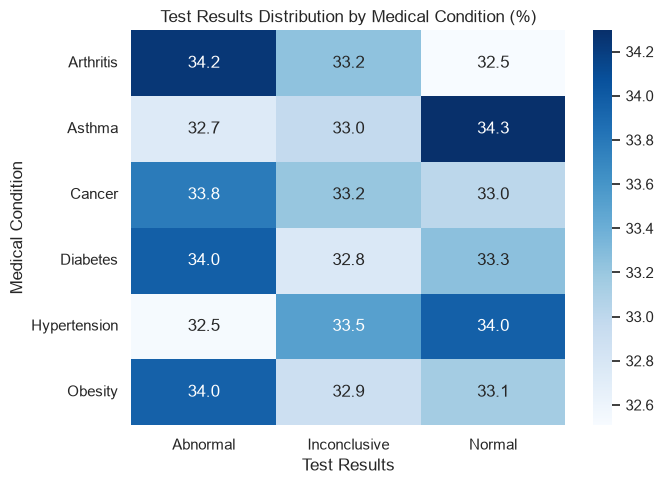

In [68]:
plt.figure(figsize=(7, 5))
sns.heatmap(condition_test_percentage,annot=True,fmt='.1f',cmap='Blues')
plt.title('Test Results Distribution by Medical Condition (%)')
plt.xlabel('Test Results')
plt.ylabel('Medical Condition')
plt.tight_layout()
plt.show()

Check target variable distribution

In [69]:
target_distribution = clean_df['Test Results'].value_counts()
target_distribution

Test Results
Abnormal        18399
Normal          18302
Inconclusive    18159
Name: count, dtype: int64

In [70]:
target_percentage = (clean_df['Test Results'].value_counts(normalize=True).mul(100).round(2))
target_percentage

Test Results
Abnormal        33.54
Normal          33.36
Inconclusive    33.10
Name: proportion, dtype: float64

## Key Insights
- Male and female patients counts are almost equal.
- Obesity has the highest average billing amount.
- Elective admissions have the highest average billing.
- Length of stay has almost no linear relationship with billing amount.
- The highest number of admissions was recorded in 2020.
- The dataset records the lowest number of admissions in 2024.